## Step 04 · EMT-TF expression (unconditional final step)

The EMT transcription-factor readout runs regardless of gate outcome and is always the *last* notebook.
Score a widened candidate panel — Snail/Zeb/Twist **plus the FOXC and PRRX families** — **gated on
detectable expression** (≥3% of cells; 10x/inDrop dropout makes rare factors uninformative). VIM is a
mesenchymal marker, **not** a transcription factor, and is excluded. Display the categorical overlay of
thresholded *expressers* on a grey manifold (reference style), not a continuous single-gene colormap.
Reads `signatures.h5ad` to inherit the manifold's house orientation + milestones (consistent across all
panels; the same malignant cells as `processed.h5ad`).

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
SEED = 1; np.random.seed(SEED)
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_in  = os.path.join(pth,'data','cancer', 'vertebrate', 'CCCA', 'claude','Lung',name)
pth_out = os.path.join(pth,'figures', 'mesencontext', 'claude','Lung',name)

In [ ]:
# load signatures data (carries oriented UMAP + milestones + pseudotime)
adata = sc.read_h5ad(os.path.join(pth_in,'signatures.h5ad')); adata

In [ ]:
# candidate EMT-TF panel: Snail/Zeb/Twist + FOXC/PRRX families (VIM excluded: marker, not TF)
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
raw = adata.raw.to_adata()
rows=[]
for gname in panel:
    if gname in raw.var_names:
        x=np.asarray(raw[:,gname].X.todense()).ravel() if hasattr(raw[:,gname].X,'todense') else np.asarray(raw[:,gname].X).ravel()
        frac=float((x>0).mean())
        rho=float(spearmanr(tn,x).correlation) if frac>0 else np.nan
        rows.append((gname,round(frac*100,1),round(rho,3)))
emt=pd.DataFrame(rows,columns=['gene','pct_expr','rho_pt']).sort_values('pct_expr',ascending=False)
print(emt.to_string(index=False))

  gene  pct_expr  rho_pt
 FOXC1       6.8   0.008
 SNAI2       5.1  -0.080
 PRRX2       4.7   0.007
  ZEB2       3.9  -0.037
 SNAI1       3.0   0.046
TWIST2       1.7   0.136
 PRRX1       1.6   0.012
  ZEB1       1.5  -0.030
TWIST1       0.2   0.004
 FOXC2       0.2   0.016


In [ ]:
# pick end-factors among DETECTABLE (>=3%) TFs by pseudotime trend: early/root (most -rho) & late/terminus (most +rho)
expr = emt[emt.pct_expr>=3.0].copy()
early = expr.sort_values('rho_pt').iloc[0]
late  = expr.sort_values('rho_pt').iloc[-1]
print('detectable (>=3%%) EMT-TFs:', expr.gene.tolist())
print('early/root factor : %s (rho=%+.3f, %.1f%% expr)'%(early.gene,early.rho_pt,early.pct_expr))
print('late/terminus     : %s (rho=%+.3f, %.1f%% expr)'%(late.gene,late.rho_pt,late.pct_expr))
print('NB: EMT axis is weak/early-loaded, end-separation small (dpt=%.2f); FOXC1 the best-expressed factor (panel-widening per the FOXC/PRRX rule)'%abs(late.rho_pt-early.rho_pt))

detectable (>=3%%) EMT-TFs: ['FOXC1', 'SNAI2', 'PRRX2', 'ZEB2', 'SNAI1']
early/root factor : SNAI2 (rho=-0.080, 5.1% expr)
late/terminus     : SNAI1 (rho=+0.046, 3.0% expr)
NB: EMT axis is weak/early-loaded, end-separation small (dpt=0.13); FOXC1 the best-expressed factor (panel-widening per the FOXC/PRRX rule)


The EMT programme is **weak and early/root-loaded** at inDrop depth: only 5 factors clear the 3% floor,
canonical TWIST1/ZEB1/FOXC2 are near/below detection. By pseudotime trend the endpoints are **SNAI2
(early/root)** and **SNAI1 (late/terminus)**, with **FOXC1** the best-expressed factor (recovered only by
widening the panel to FOXC/PRRX). End-separation is small — an honest, weakly-polarised readout.

saved expression.pdf (SNAI2 root-blue / SNAI1 terminus-red, thresholded expressers on grey manifold)


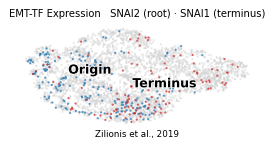

In [ ]:
# EMT-TF categorical overlay: thresholded expressers colored on a grey manifold (reference style)
g_plt = {early.gene: ('tab:blue', 0.0), late.gene: ('tab:red', 0.0)}   # threshold 0 = any detectable expression
fig, ax = plt.subplots(1,1,figsize=(3.5,1.5))
sc.pl.umap(adata, size=12, alpha=.5, frameon=False, show=False, ax=ax)          # grey base manifold
for var,(col,thr) in g_plt.items():
    sub = adata[np.asarray(adata.raw[:,var].X.todense()).ravel() > thr].copy() if hasattr(adata.raw[:,var].X,'todense') else adata[np.asarray(adata.raw[:,var].X).ravel() > thr].copy()
    sc.pl.umap(sub, na_color=col, size=12, alpha=.7, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=12, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.set_title('EMT-TF Expression   %s (root) · %s (terminus)'%(early.gene,late.gene), size=8)
ax.text(.5,-.08,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=7)
fig.savefig(os.path.join(pth_out,'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf (%s root-blue / %s terminus-red, thresholded expressers on grey manifold)'%(early.gene,late.gene))